In [1]:
config = {
    "prior":
        {
        "gamma_range": [0.05, 0.5],
        "beta_range": [0.5, 5.0],
        },
    "simulator":
        {
        "S": [1500, 2000], # int, tuple, number of Susceptible individuals or bounds for following uniform distribution
        "I": [150, 200], # int, tuple, number of Infectious individuals or bounds for following uniform distribution
        "R": [0, 50], # int, tuple, number of Recovered individuals or bounds for following uniform distribution
        "T": [100, 120],  # int, tuple, simulation duration in days or bounds for following uniform distribution
        },
    "summary": 
        {
        "type": "lstm",
        "input_dim": 3,
        "hidden_dim": 32,
        "num_layers": 2,
        "output_dim": 5,
        "dropout": 0.1,
        },
    "logger":
        {
        "name": "SIR",
        "level": "DEBUG",
        "log_file_path": "logs/sir.log",
        }
}

In [2]:
import torch
from sfmpe.tasks.SIR import SIRTask


device = 'cuda' if torch.cuda.is_available() else 'cpu'
task = SIRTask(config, device)
task.summary.to(device)

theta_0 = torch.tensor([[1.2621, 0.4558]]).to(device) 


Running 1000 simulations.:   0%|          | 0/1000 [00:00<?, ?it/s]

 Training neural network. Epochs trained: 101
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 101
        Best validation performance: 3.3753
        -------------------------
        


Drawing 1000 posterior samples:   0%|          | 0/1000 [00:00<?, ?it/s]

tensor([[1.2621, 0.4558]])
tensor([[0.6030, 0.1965]])
tensor([[0.2714, 0.1013]])


Drawing 1000 posterior samples:   0%|          | 0/1000 [00:00<?, ?it/s]

Running 1000 simulations.:   0%|          | 0/1000 [00:00<?, ?it/s]

Using SNPE-C with atomic loss
 Training neural network. Epochs trained: 21

KeyboardInterrupt: 

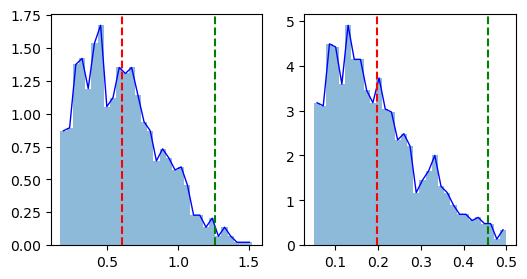

In [3]:
import torch
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence

from sfmpe.utils.plotting import dist_plot
from sbi.inference import SNPE, simulate_for_sbi
from sbi.utils import posterior_nn
from sbi.utils.user_input_checks import process_prior, process_simulator


torch.autograd.set_detect_anomaly(True)

prior, _, prior_returns_numpy = process_prior(task.prior)
configured_T = task.simulator.T
max_length = max(configured_T) if isinstance(configured_T, (tuple, list)) else int(configured_T)


def simulate_padded(theta):
    series = task.simulator.simulate(theta)
    sequence_length = series.shape[-2]
    if sequence_length > max_length:
        raise ValueError(f"Simulation length {sequence_length} exceeds {max_length}.")

    series = F.pad(series, (0, 0, 0, max_length - sequence_length))
    mask = (torch.arange(max_length, device=series.device) < sequence_length).to(series.dtype)
    mask = mask.view(*([1] * (series.ndim - 2)), max_length, 1)
    mask = mask.expand(*series.shape[:-1], 1)
    return torch.cat((series, mask), dim=-1)


simulator = process_simulator(simulate_padded, task.prior, prior_returns_numpy)
x_0 = simulator(theta_0.cpu())


class PaddedLSTMSummary(torch.nn.Module):
    def __init__(self, summary):
        super().__init__()
        self.summary = summary
        self.input_dim = summary.input_dim
        self.output_dim = summary.output_dim

    def forward(self, data):
        if data.shape[-1] != self.input_dim + 1:
            raise ValueError("Expected SIR observations plus one length-mask channel.")

        values = data[..., :self.input_dim]
        lengths = data[..., self.input_dim].sum(dim=-1).to(dtype=torch.long)
        batch_shape = values.shape[:-2]
        values = values.reshape(-1, values.shape[-2], self.input_dim)
        lengths = lengths.reshape(-1)
        packed = pack_padded_sequence(
            values, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.summary.lstm(packed)
        embedding = self.summary.fc(hidden[-1])
        return embedding.reshape(*batch_shape, self.output_dim)


embedding_net = PaddedLSTMSummary(task.summary.to("cpu"))
density_estimator = posterior_nn(
    model="maf",
    embedding_net=embedding_net,
    z_score_x=None,
)
inference = SNPE(prior=task.prior, density_estimator=density_estimator)

num_rounds = 3
num_samples = 1000
show_train_summary = True
max_num_epochs = 100
stop_after_epochs = max_num_epochs

proposal = prior

for _ in range(num_rounds):
    theta, x = simulate_for_sbi(simulator, proposal=proposal, num_simulations=num_samples)

    density_estimator = inference.append_simulations(
        theta, x, proposal=proposal
    ).train(
        show_train_summary=show_train_summary,
        stop_after_epochs=stop_after_epochs,
        max_num_epochs=max_num_epochs,
    )
    posterior = inference.build_posterior(density_estimator, sample_with="rejection")
    proposal = posterior.set_default_x(x_0)
    proposal_theta = proposal.sample((num_samples,)).unsqueeze(1)
    print(theta_0, proposal_theta.mean(dim=0), proposal_theta.std(dim=0), sep="\n")
    dist_plot(proposal_theta, pred_param=proposal_theta.mean(dim=0), true_param=theta_0.cpu())


In [ ]:
prior.sample()

tensor([[0.1076, 0.1935]])

Drawing 10000 posterior samples:   0%|          | 0/10000 [00:00<?, ?it/s]

tensor([[1.2621, 0.4558]])
tensor([[0.5446, 0.1977]])
tensor([[0.3213, 0.1148]])


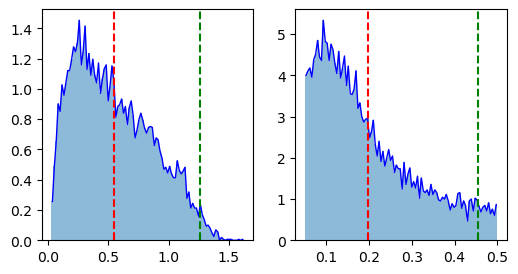

In [ ]:
from sfmpe.utils.plotting import dist_plot
prior_theta = prior.sample((10000,)).unsqueeze(1)
proposal_theta = proposal.sample((10000, )).unsqueeze(1)
print(theta_0, proposal_theta.mean(dim=0), proposal_theta.std(dim=0), sep="\n")
dist_plot(proposal_theta, pred_param=proposal_theta.mean(dim=0), true_param=theta_0.cpu())
